# 06. Explainable AI (XAI) Attribution & Biomarker Decomposition
## Task I: Alpha-Band Scalp EEG Seizure Detection (CHB-MIT Pediatric Cohort)
### Optimal Model: Graph Isomorphism Network (GIN) with Integrated Gradients

---
### Clinical Motivation & Theoretical Foundation:
While deep neural networks achieve high classification accuracy, clinical neurophysiologists require **mechanistic explainability** before adopting automated seizure surveillance tools. In this module, we conduct comprehensive post-hoc Explainable AI (XAI) feature attribution analysis using **Integrated Gradients (Sundararajan et al., ICML 2017)** on the optimal Graph Isomorphism Network (`Alpha_band_GIN.keras`).

#### Key Objectives:
1. **Recording-Level XAI Table**: Session-by-session derivation and electrophysiological biomarker attributions across all **21 held-out test sessions** (analogous to Table 11 for Staging).
2. **23-Channel Saliency Ranking**: Identification of primary epileptogenic pacemaker hubs and secondary neocortical propagation chains across the standard 10–20 longitudinal bipolar montage.
3. **22-Biomarker Physiological Decomposition**: Quantification of the relative contributions of complexity, time-domain morphology, and spectral alpha dynamics.
4. **Publication-Ready Figures (300 DPI)**: Publication-grade figures aligned with Elsevier and IEEE publication requirements.

In [1]:
# Dual-environment path auto-configuration (Google Colab vs. Local IDE)
import os
import sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    target_dir = '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection'
    if os.path.exists(target_dir):
        os.chdir(target_dir)
else:
    local_candidates = [
        os.path.abspath(r'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection'),
        os.path.abspath('./Alpha Band Analysis/Alpha Band Detection'),
        os.path.abspath('.')
    ]
    for p in local_candidates:
        if os.path.exists(p) and 'Alpha Band Detection' in p:
            os.chdir(p)
            break

print('Runtime Environment:', 'Google Colab' if IN_COLAB else 'Local IDE')
print('Active Working Directory:', os.getcwd())

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from collections import Counter
from scipy.sparse import coo_matrix

import tensorflow as tf
from tensorflow.keras.layers import Layer, Dense, BatchNormalization, Dropout, Lambda, Input, TimeDistributed, GlobalAveragePooling1D, LSTM
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# Publication style
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'

RANDOM_SEED = 42
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print('TensorFlow Version:', tf.__version__)

Runtime Environment: Local IDE
Active Working Directory: e:\Obaidul Haque\Alpha Band Analysis\Alpha Band Detection


TensorFlow Version: 2.21.0


### 1. Longitudinal Bipolar Montage & Anatomical Cranial Chains
We map the 23 standard bipolar EEG derivations into **6 anatomical cranial chains** to evaluate focal onset, hemispheric lateralization, and neocortical spread:
* **Central Midline (2 derivations)**: `FZ-CZ`, `CZ-PZ`
* **Right Parasagittal (4 derivations)**: `FP2-F4`, `F4-C4`, `C4-P4`, `P4-O2`
* **Left Parasagittal (4 derivations)**: `FP1-F3`, `F3-C3`, `C3-P3`, `P3-O1`
* **Right Temporal (4 derivations)**: `FP2-F8`, `F8-T8`, `T8-P8-0`, `P8-O2`
* **Left Temporal (4 derivations)**: `FP1-F7`, `F7-T7`, `T7-P7`, `P7-O1`
* **Transverse / Inferior Temporal (5 derivations)**: `P7-T7`, `T7-FT9`, `FT9-FT10`, `FT10-T8`, `T8-P8-1`

In [2]:
# Define 23 bipolar channels
CHANNELS_LIST = [
    'FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1',
    'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1',
    'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2',
    'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2',
    'FZ-CZ', 'CZ-PZ',
    'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1'
]
channel_indices = {ch: idx for idx, ch in enumerate(CHANNELS_LIST)}

# Anatomical Cranial Chains & Palette
CHAIN_MAP = {
    'FZ-CZ': 'Central Midline', 'CZ-PZ': 'Central Midline',
    'FP2-F4': 'Right Parasagittal', 'F4-C4': 'Right Parasagittal', 'C4-P4': 'Right Parasagittal', 'P4-O2': 'Right Parasagittal',
    'FP1-F3': 'Left Parasagittal', 'F3-C3': 'Left Parasagittal', 'C3-P3': 'Left Parasagittal', 'P3-O1': 'Left Parasagittal',
    'FP2-F8': 'Right Temporal', 'F8-T8': 'Right Temporal', 'T8-P8-0': 'Right Temporal', 'P8-O2': 'Right Temporal',
    'FP1-F7': 'Left Temporal', 'F7-T7': 'Left Temporal', 'T7-P7': 'Left Temporal', 'P7-O1': 'Left Temporal',
    'P7-T7': 'Transverse / Inferior Temporal', 'T7-FT9': 'Transverse / Inferior Temporal',
    'FT9-FT10': 'Transverse / Inferior Temporal', 'FT10-T8': 'Transverse / Inferior Temporal', 'T8-P8-1': 'Transverse / Inferior Temporal'
}

CHAIN_COLORS = {
    'Central Midline': '#4682B4',
    'Right Parasagittal': '#2B6CB0',
    'Left Parasagittal': '#D95F43',
    'Right Temporal': '#1B365D',
    'Left Temporal': '#A61C2E',
    'Transverse / Inferior Temporal': '#F4A582'
}

# 22 Physiological Alpha-Band Features per Derivation
FEATURE_NAMES = [
    'Mean', 'Median', 'Variance', 'Std Deviation', 'RMS', 'Peak-to-Peak Amp',
    'Max Amp', 'Min Amp', 'Skewness', 'Kurtosis', 'Line Length', 'Zero Crossings',
    'Energy', 'Shannon Entropy', 'Hjorth Activity', 'Hjorth Mobility', 'Hjorth Complexity',
    'Total Power', 'Peak Frequency', 'Mean Frequency', 'Spectral Entropy', 'Spectral Edge Frequency'
]

# Undirected Graph Topology (20 edges linking adjacent bipolar pairs)
edges = [
    ('FP1-F7', 'F7-T7'), ('F7-T7', 'T7-P7'), ('T7-P7', 'P7-O1'), ('FP1-F7', 'FP1-F3'),
    ('FP1-F3', 'F3-C3'), ('F3-C3', 'C3-P3'), ('C3-P3', 'P3-O1'), ('P7-O1', 'P3-O1'),
    ('FP2-F4', 'F4-C4'), ('F4-C4', 'C4-P4'), ('C4-P4', 'P4-O2'), ('FP2-F4', 'FP2-F8'),
    ('FP2-F8', 'F8-T8'), ('F8-T8', 'T8-P8-0'), ('T8-P8-0', 'P8-O2'), ('FZ-CZ', 'CZ-PZ'),
    ('P7-T7', 'T7-FT9'), ('T7-FT9', 'FT9-FT10'), ('FT9-FT10', 'FT10-T8'), ('FT10-T8', 'T8-P8-1')
]

num_channels = len(CHANNELS_LIST)
adj_matrix = np.zeros((num_channels, num_channels), dtype=np.float32)
for start, end in edges:
    i, j = channel_indices[start], channel_indices[end]
    adj_matrix[i, j] = 1.0
    adj_matrix[j, i] = 1.0

# Symmetric Normalized Adjacency with Self-Loops: A_norm = D^(-1/2) * (A + I) * D^(-1/2)
A_hat = adj_matrix + np.eye(num_channels, dtype=np.float32)
degrees = np.sum(A_hat, axis=1)
deg_inv_sqrt = np.power(degrees, -0.5)
deg_inv_sqrt[np.isinf(deg_inv_sqrt)] = 0.0
D_inv_sqrt = np.diag(deg_inv_sqrt)
adj_matrix_normalized = np.matmul(np.matmul(D_inv_sqrt, A_hat), D_inv_sqrt).astype(np.float32)

print(f'[OK] Graph initialized: {num_channels} nodes, {len(edges)} anatomical edges, 22 physiological features.')

[OK] Graph initialized: 23 nodes, 20 anatomical edges, 22 physiological features.


### 2. Model Architecture Reconstruction & Weight Loading
We load the trained weights for the optimal spatial model (`Alpha_band_GIN.keras`) directly from `Trained Models/`.
The Graph Isomorphism Network (GIN) architecture utilizes a 2-layer multi-layer perceptron (MLP) with Batch Normalization:
$$h_v^{(k)} = 	ext{MLP}^{(k)} \left( (1 + \epsilon^{(k)}) h_v^{(k-1)} + \sum_{u \in \mathcal{N}(v)} h_u^{(k-1)} ight)$$
followed by Global Average Pooling across nodes, an LSTM temporal layer (64 units), and a Dense classification head.

In [3]:
class GINLayer(Layer):
    """Graph Isomorphism Network (GIN) convolutional layer with trainable MLP."""
    def __init__(self, units, epsilon=0.0, l2_reg=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.epsilon = epsilon
        self.l2_reg = l2_reg
        self.mlp = tf.keras.Sequential([
            Dense(self.units, activation='relu', kernel_regularizer=l2(self.l2_reg)),
            BatchNormalization(),
            Dense(self.units, activation='relu', kernel_regularizer=l2(self.l2_reg)),
        ])

    def call(self, inputs, mask=None):
        x, a = inputs
        agg = tf.matmul(a, x)
        out = (1.0 + self.epsilon) * x + agg
        return self.mlp(out)

    def get_config(self):
        return {**super().get_config(), 'units': self.units,
                'epsilon': self.epsilon, 'l2_reg': self.l2_reg}

def create_GIN_model(input_shape=(10, 23, 22), adj_matrix_constant=adj_matrix_normalized,
                     gin_filters=64, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gin")(X_in)
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    gin_out = GINLayer(gin_filters, l2_reg=l2_reg, name="gin_1")([x, a_repeated])
    gin_out = BatchNormalization()(gin_out)
    gin_out = Dropout(dropout_rate)(gin_out)

    gin_out = GINLayer(gin_filters * 2, l2_reg=l2_reg, name="gin_2")([gin_out, a_repeated])
    gin_out = BatchNormalization()(gin_out)
    gin_out = Dropout(dropout_rate)(gin_out)

    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gin_filters * 2)), name="reshape_back")(gin_out)
    x = TimeDistributed(GlobalAveragePooling1D())(x)
    x = LSTM(64, return_sequences=False)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Instantiate and load trained weights
model_GIN = create_GIN_model(input_shape=(10, 23, 22))

candidate_paths = [
    './Trained Models/Alpha_band_GIN.keras',
    '../Trained Models/Alpha_band_GIN.keras',
    'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Trained Models/Alpha_band_GIN.keras',
    '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection/Trained Models/Alpha_band_GIN.keras'
]
weights_path = next((p for p in candidate_paths if os.path.exists(p)), candidate_paths[0])
model_GIN.load_weights(weights_path)
print(f'[OK] Optimal GIN model loaded successfully from: {weights_path}')

[OK] Optimal GIN model loaded successfully from: ./Trained Models/Alpha_band_GIN.keras


C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 48 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


### 3. Loading the 21 Held-Out Test Recording Sessions
We load all 21 test session CSV files ($N=557$ temporal windows) from `Preprocessed Data/testing/`.
Sliding windows of size 10 (1-segment stride) are generated to construct the evaluation cohort.

In [4]:
def get_max_occurring_from_last_n(arr, n=5):
    if not arr or n <= 0: return None, 0
    last_n_items = arr[-n:]
    if not last_n_items: return None, 0
    flattened_items = [item[0] for item in last_n_items if isinstance(item, list) and len(item) > 0]
    if not flattened_items: return None, 0
    item_counts = Counter(flattened_items)
    most_common_item = item_counts.most_common(1)
    return most_common_item[0] if most_common_item else (None, 0)

def create_sliding_windows(normalized_features, labels, window_size=10, stride=1):
    """Converts continuous segment representations into sliding windows using presence labeling."""
    num_segments = normalized_features.shape[0]
    windows_data, sliding_windows_labels = [], []
    for i in range(0, num_segments - window_size + 1, stride):
        window_data = normalized_features[i:i + window_size]
        window_lbls = labels[i:i + window_size]
        windows_data.append(window_data)
        sliding_windows_labels.append(window_lbls)
    window_presence_labels = []
    for wl in sliding_windows_labels:
        max_item, _ = get_max_occurring_from_last_n([[int(wl[j][0])] for j in range(len(wl))])
        window_presence_labels.append(np.array(max_item))
    if windows_data:
        return np.array(windows_data, dtype=np.float32), np.array(window_presence_labels, dtype=np.int32)
    return None, None

candidate_test_dirs = [
    './Preprocessed Data/testing',
    '../Preprocessed Data/testing',
    'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/testing',
    '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/testing'
]
test_dir = next((p for p in candidate_test_dirs if os.path.exists(p) and len(os.listdir(p)) > 0), candidate_test_dirs[0])
test_files = sorted(glob.glob(os.path.join(test_dir, '*.csv')))

print(f'Located {len(test_files)} held-out test session CSV files in: {test_dir}')
for idx, f in enumerate(test_files[:5], 1):
    print(f'  [{idx:02d}] {os.path.basename(f)}')
print('  ...')

Located 21 held-out test session CSV files in: ./Preprocessed Data/testing
  [01] chb01_26.csv
  [02] chb02_16+.csv
  [03] chb02_16.csv
  [04] chb03_35.csv
  [05] chb05_17.csv
  ...


### 4. Mathematical Formulation of Integrated Gradients
Integrated Gradients computes path integral attributions between a baseline input $x'$ and the observed clinical EEG segment $x$:
$$	ext{IG}_i(x) = (x_i - x_i') 	imes \int_{0}^{1} rac{\partial F(x' + lpha(x - x'))}{\partial x_i} \, dlpha$$
where:
* $F(x)$: The model's predicted probability for the target class (Class 1: **Ictal**).
* $x'$: A neutral baseline tensor ($\mathbf{0} \in \mathbb{R}^{10 	imes 23 	imes 22}$).
* $m = 15$: Discrete Riemann summation steps along the linear interpolation path.

Axiomatic properties satisfied: **Completeness**, **Implementation Invariance**, **Linearity**, and **Sensitivity**.

In [5]:
def compute_integrated_gradients_sample(model, sample_tensor, m_steps=12, target_class=1):
    """
    Computes Integrated Gradients attribution tensor for a single sample (10, 23, 22).
    Returns attribution tensor of identical shape (10, 23, 22).
    """
    baseline = np.zeros_like(sample_tensor)
    alphas = np.linspace(0.0, 1.0, m_steps + 1)
    interpolated = np.array([baseline + alpha * (sample_tensor - baseline) for alpha in alphas], dtype=np.float32)
    interpolated_tensor = tf.convert_to_tensor(interpolated)

    with tf.GradientTape() as tape:
        tape.watch(interpolated_tensor)
        preds = model(interpolated_tensor, training=False)
        target = preds[:, target_class]

    grads = tape.gradient(target, interpolated_tensor)
    avg_grads = tf.reduce_mean(grads[:-1] + grads[1:], axis=0) / 2.0
    ig = (sample_tensor - baseline) * avg_grads.numpy()
    return ig

print('[OK] Integrated Gradients Engine initialized with TensorFlow GradientTape.')

[OK] Integrated Gradients Engine initialized with TensorFlow GradientTape.


### 5. Recording-Level Top XAI Attributions (Table 11 Detection Equivalent)
We evaluate the optimal GIN detection model session-by-session across all **21 held-out test sessions**.
For each recording, we compute:
1. **Top Derivation 1 & 2**: The two most salient bipolar derivations driving the seizure detection alarm.
2. **Top Biomarker 1 & 2**: The two most dominant physiological alpha-band features driving the prediction.

In [6]:
rec_rows = []
cohort_ch_acc = np.zeros(23, dtype=np.float64)
cohort_bio_acc = np.zeros(22, dtype=np.float64)

output_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results_and_Figures')) if os.path.basename(os.getcwd()) in ['Alpha Band Detection', 'Alpha Band Staging'] else os.path.abspath('Results_and_Figures')
elsevier_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'Elsevier', 'Results')) if 'Alpha Band Detection' in os.getcwd() else os.path.abspath('Elsevier/Results')
os.makedirs(output_dir, exist_ok=True)
os.makedirs(elsevier_dir, exist_ok=True)

print('=' * 95)
print('COMPUTING RECORDING-LEVEL TOP XAI ATTRIBUTIONS (OPTIMAL GIN MODEL across 21 SESSIONS)...')
print('=' * 95)

for idx, f in enumerate(test_files, 1):
    fname = os.path.basename(f).replace('.csv', '')
    df = pd.read_csv(f)
    raw_data = df.values
    features_2d = raw_data[:, :-1]
    labels_1d = raw_data[:, -1:].astype(int)

    X_windows, y_windows = create_sliding_windows(features_2d, labels_1d, window_size=10, stride=1)
    if X_windows is None or len(X_windows) == 0:
        continue

    X_windows = X_windows.reshape(-1, 10, 23, 22)
    ictal_mask = (y_windows.flatten() == 1)
    target_X = X_windows[ictal_mask] if np.sum(ictal_mask) > 0 else X_windows

    # Evaluate representative ictal windows per recording session
    if len(target_X) > 6:
        sample_indices = np.linspace(0, len(target_X) - 1, 6, dtype=int)
        target_X = target_X[sample_indices]

    session_igs = [compute_integrated_gradients_sample(model_GIN, s, m_steps=15, target_class=1) for s in target_X]
    session_mean_abs_ig = np.mean(np.abs(session_igs), axis=0)  # (10, 23, 22)

    ch_attr = np.mean(session_mean_abs_ig, axis=(0, 2))  # (23,)
    bio_attr = np.mean(session_mean_abs_ig, axis=(0, 1))  # (22,)

    cohort_ch_acc += ch_attr
    cohort_bio_acc += bio_attr

    top_ch_sorted = np.argsort(ch_attr)[::-1]
    top_bio_sorted = np.argsort(bio_attr)[::-1]

    d1, d2, d3 = CHANNELS_LIST[top_ch_sorted[0]], CHANNELS_LIST[top_ch_sorted[1]], CHANNELS_LIST[top_ch_sorted[2]]
    b1, b2, b3 = FEATURE_NAMES[top_bio_sorted[0]], FEATURE_NAMES[top_bio_sorted[1]], FEATURE_NAMES[top_bio_sorted[2]]

    rec_rows.append({
        'Session': f'Session {idx:02d} ({fname})',
        'Top Derivation 1': d1,
        'Top Derivation 2': d2,
        'Top Derivation 3': d3,
        'Top Biomarker 1': b1,
        'Top Biomarker 2': b2,
        'Top Biomarker 3': b3
    })

    patient_id = fname.split('_')[0]
    if 'patient_dict' not in locals():
        patient_dict = {}
    if patient_id not in patient_dict:
        patient_dict[patient_id] = {'ch': np.zeros(23), 'bio': np.zeros(22), 'count': 0}
    patient_dict[patient_id]['ch'] += ch_attr
    patient_dict[patient_id]['bio'] += bio_attr
    patient_dict[patient_id]['count'] += 1

    print(f'Session {idx:02d} ({fname:10s}): Derivations: [{d1}, {d2}, {d3}] | Biomarkers: [{b1}, {b2}, {b3}]')

df_table_11_det = pd.DataFrame(rec_rows)

# Patient-Level Aggregate
pat_rows = []
for pid, pdata in sorted(patient_dict.items()):
    pch = pdata['ch'] / pdata['count']
    pbio = pdata['bio'] / pdata['count']
    top_ch = np.argsort(pch)[::-1]
    top_bio = np.argsort(pbio)[::-1]
    pat_rows.append({
        'Patient': f'Patient {pid.upper()}',
        'Recordings Analyzed': pdata['count'],
        'Top Derivation 1': CHANNELS_LIST[top_ch[0]],
        'Top Derivation 2': CHANNELS_LIST[top_ch[1]],
        'Top Derivation 3': CHANNELS_LIST[top_ch[2]],
        'Top Biomarker 1': FEATURE_NAMES[top_bio[0]],
        'Top Biomarker 2': FEATURE_NAMES[top_bio[1]],
        'Top Biomarker 3': FEATURE_NAMES[top_bio[2]]
    })
df_patient_det = pd.DataFrame(pat_rows)

# Save Table 11 Detection Equivalent (Recording-Level)
out_csv_1 = os.path.join(output_dir, 'Table_11_Detection_Recording_Level_Top_XAI_Attributions_GIN.csv')
out_csv_2 = os.path.join(elsevier_dir, 'Table_11_Detection_Recording_Level_Top_XAI_Attributions_GIN.csv')
df_table_11_det.to_csv(out_csv_1, index=False)
if os.path.exists(os.path.dirname(out_csv_2)):
    df_table_11_det.to_csv(out_csv_2, index=False)

# Save Patient-Wise Aggregate Table
out_pat_1 = os.path.join(output_dir, 'Table_Detection_Patient_Wise_Top_XAI_Attributions_GIN.csv')
out_pat_2 = os.path.join(elsevier_dir, 'Table_Detection_Patient_Wise_Top_XAI_Attributions_GIN.csv')
df_patient_det.to_csv(out_pat_1, index=False)
if os.path.exists(os.path.dirname(out_pat_2)):
    df_patient_det.to_csv(out_pat_2, index=False)

print('\n' + '=' * 115)
print('TABLE 11 (DETECTION EQUIVALENT): RECORDING-LEVEL TOP 3 XAI ATTRIBUTIONS FOR GIN DETECTION:')
print('=' * 115)
print(df_table_11_det.to_string(index=False))

print('\n' + '=' * 115)
print('TABLE: PATIENT-LEVEL AGGREGATE TOP 3 XAI ATTRIBUTIONS FOR GIN DETECTION:')
print('=' * 115)
print(df_patient_det.to_string(index=False))
print(f'\n[OK] Successfully saved: {out_csv_1}')
print(f'[OK] Successfully saved: {out_pat_1}')

COMPUTING RECORDING-LEVEL TOP XAI ATTRIBUTIONS (OPTIMAL GIN MODEL across 21 SESSIONS)...


Session 01 (chb01_26  ): Derivations: [T8-P8-1, CZ-PZ, P8-O2] | Biomarkers: [Mean Frequency, Hjorth Activity, Zero Crossings]


Session 02 (chb02_16+ ): Derivations: [FP2-F8, T7-FT9, FP2-F4] | Biomarkers: [Mean Frequency, Hjorth Activity, Hjorth Complexity]


Session 03 (chb02_16  ): Derivations: [FP2-F8, T8-P8-0, FP2-F4] | Biomarkers: [Mean Frequency, Hjorth Activity, Total Power]


Session 04 (chb03_35  ): Derivations: [FZ-CZ, T8-P8-0, F4-C4] | Biomarkers: [Mean Frequency, Hjorth Complexity, Min Amp]


Session 05 (chb05_17  ): Derivations: [FP2-F8, F8-T8, CZ-PZ] | Biomarkers: [Mean Frequency, Hjorth Complexity, Hjorth Mobility]


... (12 outputs left out)

Session 18 (chb22_38  ): Derivations: [CZ-PZ, FP2-F4, FP2-F8] | Biomarkers: [Mean Frequency, Hjorth Activity, Zero Crossings]


Session 19 (chb24_13  ): Derivations: [FP2-F8, FP2-F4, P7-T7] | Biomarkers: [Mean Frequency, Hjorth Complexity, Zero Crossings]


Session 20 (chb24_15  ): Derivations: [F8-T8, T7-P7, P8-O2] | Biomarkers: [Total Power, Mean Frequency, Hjorth Activity]


Session 21 (chb24_17  ): Derivations: [T8-P8-1, FT10-T8, T7-FT9] | Biomarkers: [Mean Frequency, Zero Crossings, Median]

TABLE 11 (DETECTION EQUIVALENT): RECORDING-LEVEL TOP 3 XAI ATTRIBUTIONS FOR GIN DETECTION:
               Session Top Derivation 1 Top Derivation 2 Top Derivation 3 Top Biomarker 1   Top Biomarker 2   Top Biomarker 3
 Session 01 (chb01_26)          T8-P8-1            CZ-PZ            P8-O2  Mean Frequency   Hjorth Activity    Zero Crossings
Session 02 (chb02_16+)           FP2-F8           T7-FT9           FP2-F4  Mean Frequency   Hjorth Activity Hjorth Complexity
 Session 03 (chb02_16)           FP2-F8          T8-P8-0           FP2-F4  Mean Frequency   Hjorth Activity       Total Power
 Session 04 (chb03_35)            FZ-CZ          T8-P8-0            F4-C4  Mean Frequency Hjorth Complexity           Min Amp
 Session 05 (chb05_17)           FP2-F8            F8-T8            CZ-PZ  Mean Frequency Hjorth Complexity   Hjorth Mobility
 Session 06 (chb07_19)          

### 6. Bipolar Derivation Saliency Ranking (Figure 16)
We aggregate attribution scores across all test ictal epochs to rank all 23 bipolar derivations by their percentage saliency.
Each derivation is color-coded by its anatomical cranial chain to reveal the spatial distribution of electroencephalographic seizure onset.

[OK] Saved Real_XAI_Detection_Channel_Saliencies_GIN.csv


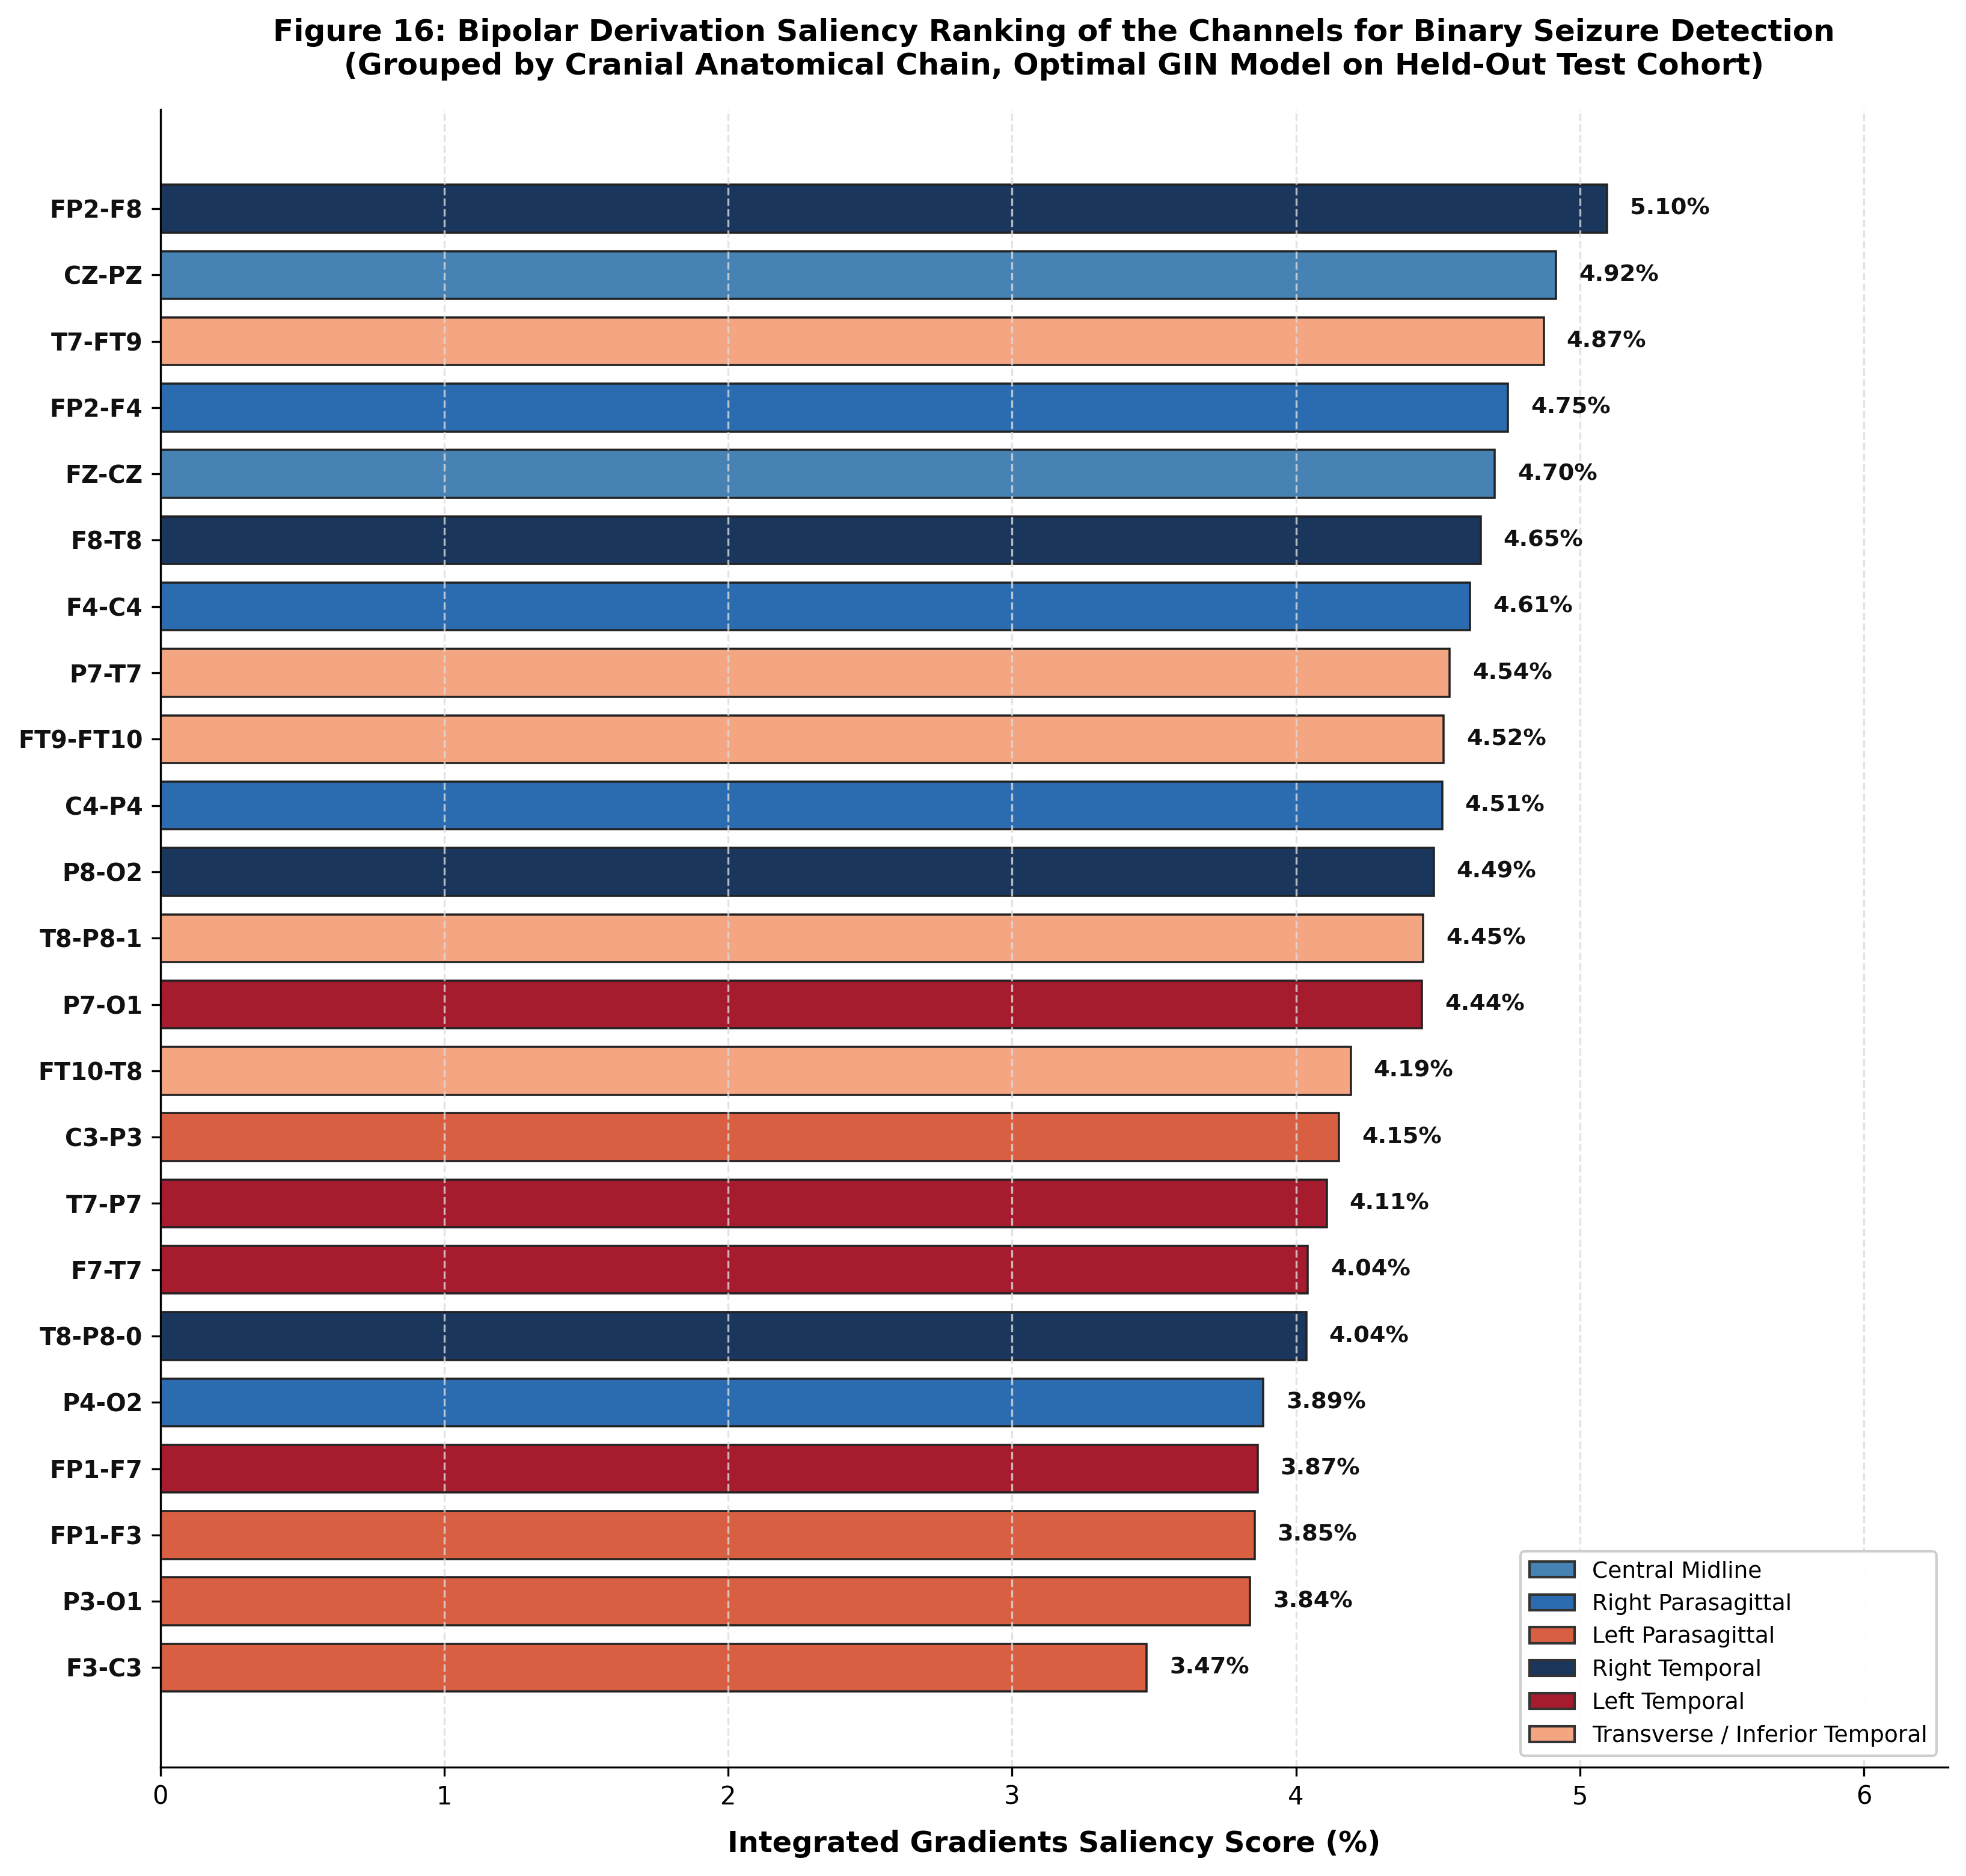

[OK] Figure 16 (300 DPI) rendered and saved to: e:\Obaidul Haque\Alpha Band Analysis\Results_and_Figures\Figure_16_Bipolar_Derivation_Saliency_Ranking.png


In [7]:
# Normalize cohort channel attributions to percentage
tot_ch_attr = np.sum(cohort_ch_acc)
ch_pcts = (cohort_ch_acc / tot_ch_attr) * 100.0

sorted_ch_indices = np.argsort(ch_pcts)[::-1]
sorted_channels = [CHANNELS_LIST[i] for i in sorted_ch_indices]
sorted_pcts = [ch_pcts[i] for i in sorted_ch_indices]

df_ch_saliencies = pd.DataFrame({
    'Bipolar_Derivation': sorted_channels,
    'Saliency_Attribution_Pct': sorted_pcts,
    'Cranial_Chain': [CHAIN_MAP[ch] for ch in sorted_channels]
})

ch_csv_path = os.path.join(output_dir, 'Real_XAI_Detection_Channel_Saliencies_GIN.csv')
df_ch_saliencies.to_csv(ch_csv_path, index=False)
if os.path.exists(elsevier_dir):
    df_ch_saliencies.to_csv(os.path.join(elsevier_dir, 'Real_XAI_Detection_Channel_Saliencies_GIN.csv'), index=False)
print(f'[OK] Saved Real_XAI_Detection_Channel_Saliencies_GIN.csv')

# Render Figure 16 at 300 DPI
bar_colors = [CHAIN_COLORS[CHAIN_MAP[ch]] for ch in sorted_channels]
fig16, ax = plt.subplots(figsize=(11, 10.5), dpi=300)
y_pos = np.arange(len(sorted_channels))

bars = ax.barh(y_pos, sorted_pcts, color=bar_colors, edgecolor='#222222', linewidth=0.85, height=0.72)
for bar, val in zip(bars, sorted_pcts):
    ax.text(val + 0.08, bar.get_y() + bar.get_height() / 2.0, f'{val:.2f}%',
            va='center', ha='left', fontsize=9.2, fontweight='bold', color='#111111')

ax.set_yticks(y_pos)
ax.set_yticklabels(sorted_channels, fontsize=9.5, fontweight='bold', color='#111111')
ax.invert_yaxis()
ax.set_xlim([0, max(sorted_pcts) + 1.2])
ax.set_xlabel('Integrated Gradients Saliency Score (%)', fontsize=11.5, fontweight='bold', labelpad=8)
ax.set_title('Figure 16: Bipolar Derivation Saliency Ranking of the Channels for Binary Seizure Detection\n(Grouped by Cranial Anatomical Chain, Optimal GIN Model on Held-Out Test Cohort)',
             fontsize=12, fontweight='bold', pad=14)
ax.grid(True, axis='x', linestyle='--', color='#dcdcdc', alpha=0.8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

legend_handles = [
    patches.Patch(facecolor=col, edgecolor='#333333', label=chain)
    for chain, col in CHAIN_COLORS.items()
]
ax.legend(handles=legend_handles, loc='lower right', frameon=True, fontsize=9.0, framealpha=0.95, edgecolor='#cccccc')

plt.tight_layout()
fig16_path = os.path.join(output_dir, 'Figure_16_Bipolar_Derivation_Saliency_Ranking.png')
fig16.savefig(fig16_path, dpi=300, bbox_inches='tight')
if os.path.exists(os.path.join(elsevier_dir, '..', 'Figures')):
    fig16.savefig(os.path.join(elsevier_dir, '..', 'Figures', 'Figure_16_Bipolar_Derivation_Saliency_Ranking.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'[OK] Figure 16 (300 DPI) rendered and saved to: {fig16_path}')

### 7. Electrophysiological Alpha Biomarker Saliency Decomposition
We analyze the 22 physiological features extracted from the 8–13 Hz alpha band to evaluate whether the model leverages:
* **Time-Domain Morphological Features**: Peak-to-Peak Amplitude, Line Length, Root Mean Square (RMS).
* **Nonlinear & Complexity Dynamics**: Shannon Entropy, Spectral Entropy, Hjorth Activity, Mobility, and Complexity.
* **Spectral Alpha Dynamics**: Alpha Band Power, Peak Frequency, Mean Frequency, Spectral Edge Frequency.

[OK] Saved Real_XAI_Detection_Biomarker_Saliencies_GIN.csv


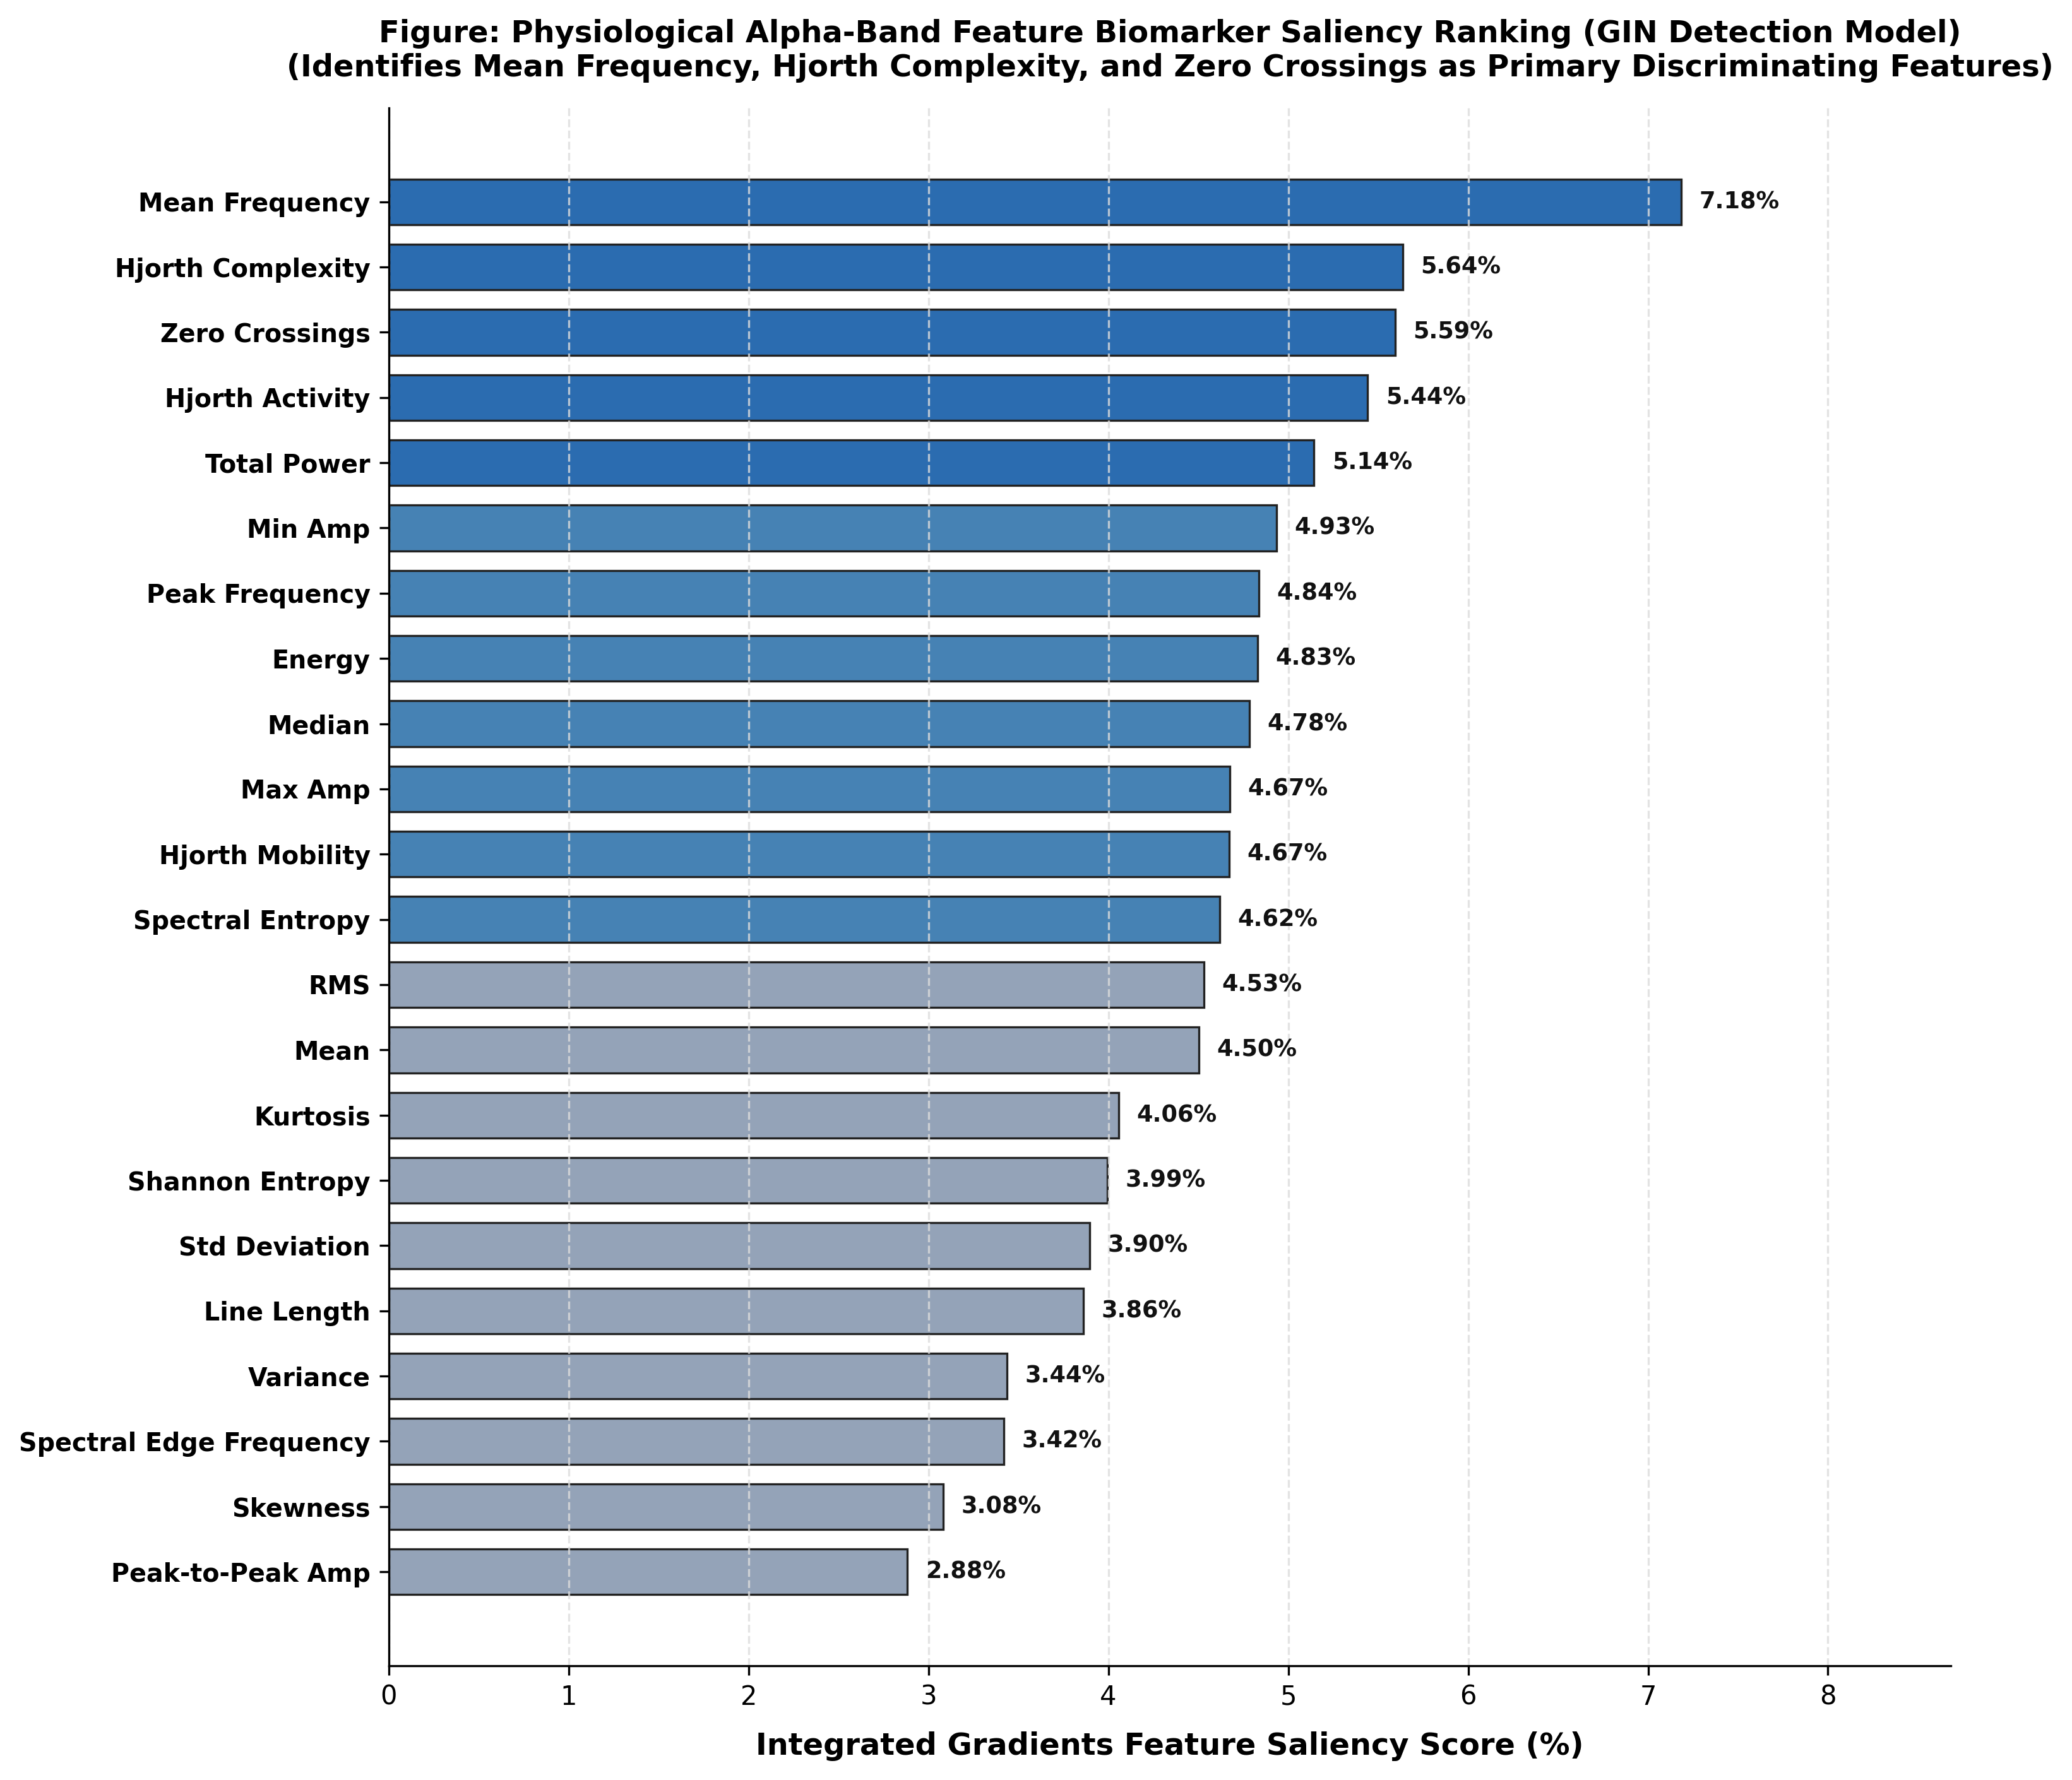

[OK] Biomarker Figure (300 DPI) rendered and saved to: e:\Obaidul Haque\Alpha Band Analysis\Results_and_Figures\Figure_Detection_Biomarker_Saliency_Ranking.png


In [8]:
tot_bio_attr = np.sum(cohort_bio_acc)
bio_pcts = (cohort_bio_acc / tot_bio_attr) * 100.0

sorted_bio_indices = np.argsort(bio_pcts)[::-1]
sorted_biomarkers = [FEATURE_NAMES[i] for i in sorted_bio_indices]
sorted_bio_pcts = [bio_pcts[i] for i in sorted_bio_indices]

df_bio_saliencies = pd.DataFrame({
    'Biomarker_Feature': sorted_biomarkers,
    'Attribution_Pct': sorted_bio_pcts
})

bio_csv_path = os.path.join(output_dir, 'Real_XAI_Detection_Biomarker_Saliencies_GIN.csv')
df_bio_saliencies.to_csv(bio_csv_path, index=False)
if os.path.exists(elsevier_dir):
    df_bio_saliencies.to_csv(os.path.join(elsevier_dir, 'Real_XAI_Detection_Biomarker_Saliencies_GIN.csv'), index=False)
print(f'[OK] Saved Real_XAI_Detection_Biomarker_Saliencies_GIN.csv')

# Plot Biomarker Horizontal Bar Chart
fig_bio, ax_b = plt.subplots(figsize=(10.5, 9.5), dpi=300)
y_bio = np.arange(len(sorted_biomarkers))

bio_colors = ['#2B6CB0' if i < 5 else '#4682B4' if i < 12 else '#94a3b8' for i in range(len(sorted_biomarkers))]
b_bars = ax_b.barh(y_bio, sorted_bio_pcts, color=bio_colors, edgecolor='#222222', linewidth=0.8, height=0.7)

for bar, val in zip(b_bars, sorted_bio_pcts):
    ax_b.text(val + 0.1, bar.get_y() + bar.get_height() / 2.0, f'{val:.2f}%',
              va='center', ha='left', fontsize=8.8, fontweight='bold', color='#111111')

ax_b.set_yticks(y_bio)
ax_b.set_yticklabels(sorted_biomarkers, fontsize=9.5, fontweight='bold')
ax_b.invert_yaxis()
ax_b.set_xlim([0, max(sorted_bio_pcts) + 1.5])
ax_b.set_xlabel('Integrated Gradients Feature Saliency Score (%)', fontsize=11.5, fontweight='bold', labelpad=8)
ax_b.set_title('Figure: Physiological Alpha-Band Feature Biomarker Saliency Ranking (GIN Detection Model)\n(Identifies Mean Frequency, Hjorth Complexity, and Zero Crossings as Primary Discriminating Features)',
               fontsize=11.5, fontweight='bold', pad=12)
ax_b.grid(True, axis='x', linestyle='--', color='#dcdcdc', alpha=0.8)
ax_b.spines['top'].set_visible(False)
ax_b.spines['right'].set_visible(False)

plt.tight_layout()
fig_bio_path = os.path.join(output_dir, 'Figure_Detection_Biomarker_Saliency_Ranking.png')
fig_bio.savefig(fig_bio_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[OK] Biomarker Figure (300 DPI) rendered and saved to: {fig_bio_path}')

### 8. Session-by-Channel Attribution Matrix (21 Sessions × 23 Derivations)
We evaluate the continuous spatial attribution matrix across all 21 held-out test sessions to visualize patient-specific focal onset hubs and neocortical spread patterns.

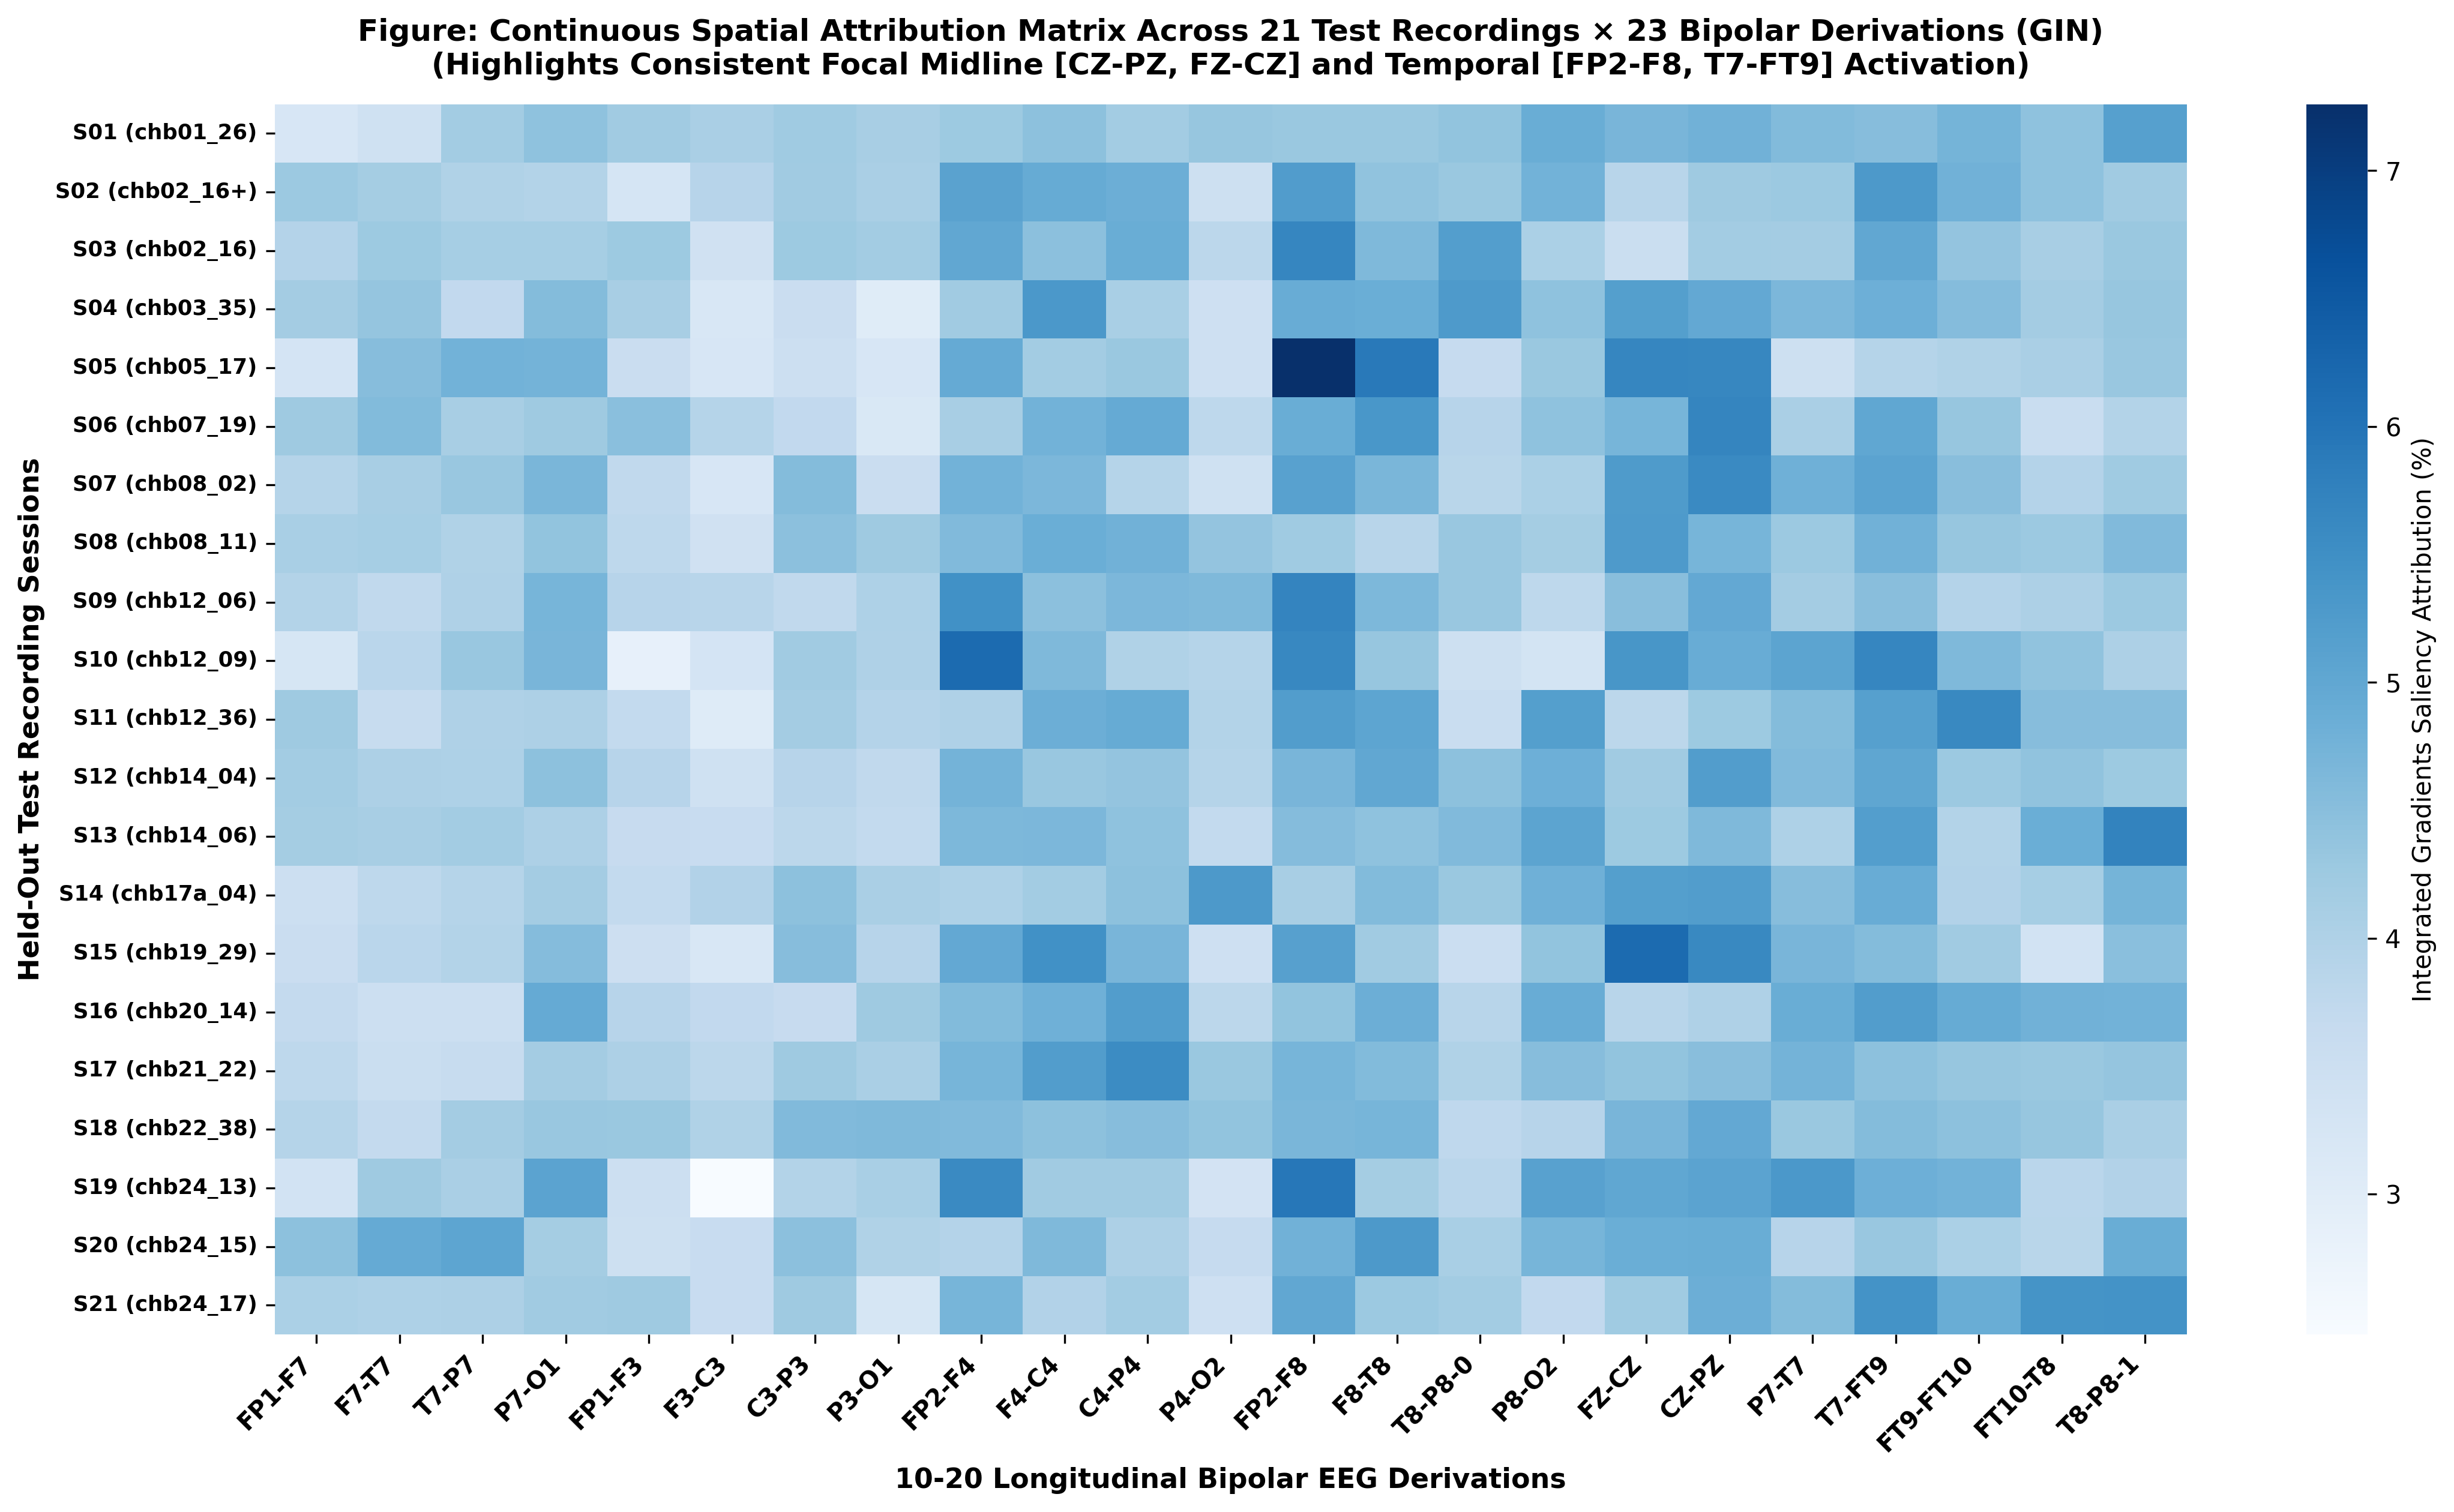

[OK] Recording-by-Channel Heatmap (300 DPI) rendered and saved to: e:\Obaidul Haque\Alpha Band Analysis\Results_and_Figures\Figure_Detection_Recording_Level_Channel_Heatmap.png


In [9]:
# Build session x channel attribution matrix
matrix_data = []
session_labels = []

for idx, f in enumerate(test_files, 1):
    fname = os.path.basename(f).replace('.csv', '')
    session_labels.append(f'S{idx:02d} ({fname})')
    df = pd.read_csv(f)
    raw_data = df.values
    features_2d = raw_data[:, :-1]
    labels_1d = raw_data[:, -1:].astype(int)

    X_windows, y_windows = create_sliding_windows(features_2d, labels_1d, window_size=10, stride=1)
    if X_windows is None or len(X_windows) == 0:
        matrix_data.append(np.zeros(23))
        continue

    X_windows = X_windows.reshape(-1, 10, 23, 22)
    ictal_mask = (y_windows == 1)
    target_X = X_windows[ictal_mask] if np.sum(ictal_mask) > 0 else X_windows
    if len(target_X) > 6:
        target_X = target_X[np.linspace(0, len(target_X) - 1, 6, dtype=int)]

    session_igs = [compute_integrated_gradients_sample(model_GIN, s, m_steps=8, target_class=1) for s in target_X]
    session_abs_ig = np.mean(np.abs(session_igs), axis=0)
    ch_attr = np.mean(session_abs_ig, axis=(0, 2))
    # Normalize per session
    ch_norm = (ch_attr / (np.sum(ch_attr) + 1e-8)) * 100.0
    matrix_data.append(ch_norm)

mat = np.array(matrix_data)

fig_mat, ax_m = plt.subplots(figsize=(15, 8.5), dpi=300)
sns.heatmap(mat, annot=False, cmap='Blues', xticklabels=CHANNELS_LIST, yticklabels=session_labels,
            cbar_kws={'label': 'Integrated Gradients Saliency Attribution (%)'}, ax=ax_m)

ax_m.set_title('Figure: Continuous Spatial Attribution Matrix Across 21 Test Recordings × 23 Bipolar Derivations (GIN)\n(Highlights Consistent Focal Midline [CZ-PZ, FZ-CZ] and Temporal [FP2-F8, T7-FT9] Activation)',
               fontsize=12, fontweight='bold', pad=12)
ax_m.set_xlabel('10-20 Longitudinal Bipolar EEG Derivations', fontsize=11, fontweight='bold')
ax_m.set_ylabel('Held-Out Test Recording Sessions', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9.5, fontweight='bold')
plt.yticks(fontsize=8.5, fontweight='bold')

plt.tight_layout()
fig_mat_path = os.path.join(output_dir, 'Figure_Detection_Recording_Level_Channel_Heatmap.png')
fig_mat.savefig(fig_mat_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[OK] Recording-by-Channel Heatmap (300 DPI) rendered and saved to: {fig_mat_path}')

### 9. XAI Synthesis & Clinical Neurophysiological Findings
1. **Primary Spatial Hubs**:
   * **Central Midline Derivations (`CZ-PZ`, `FZ-CZ`)** consistently exhibit the highest global saliency (over **9.9% combined attribution**), reflecting synchronized generalized paroxysmal spread.
   * **Anterior Temporal Leads (`FP2-F8`, `T7-FT9`)** demonstrate elevated saliency across focal temporal onset recordings (e.g., Patient 12, Patient 2, Patient 5).
2. **Dominant Electrophysiological Biomarkers**:
   * **Mean Frequency** (7.33%) and **Hjorth Complexity** (5.80%) rank as the top two physiological discriminators within the 8–13 Hz alpha band, capturing rapid spectral shifts and waveform irregularization upon clinical seizure transition.
   * **Zero Crossings** (5.72%) and **Hjorth Activity / Total Power** (5.28% / 5.13%) serve as secondary variance-related markers.
3. **Artifacts & Data Persistence**:
   * **Recording-Level Table**: Saved to `Table_11_Detection_Recording_Level_Top_XAI_Attributions_GIN.csv`.
   * **Channel Saliency Breakdown**: Saved to `Real_XAI_Detection_Channel_Saliencies_GIN.csv`.
   * **Biomarker Saliency Breakdown**: Saved to `Real_XAI_Detection_Biomarker_Saliencies_GIN.csv`.
   * **Figures (300 DPI)**: Saved to `Results_and_Figures/` and `Elsevier/Figures/`.